<a href="https://colab.research.google.com/github/vineet992005kumar-coder/brain-gene-expression/blob/main/brain_gene_expression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
!pip install abagen

In [27]:
p = '/usr/local/lib/python3.13/dist-packages/abagen/probes_.py'
s = open(p).read()
s = s.replace("micro.set_axis(symbols, axis=1, inplace=False)",
              "micro.set_axis(symbols, axis=1)")
open(p, 'w').write(s)
print("fixed")

fixed


In [28]:
import abagen

In [29]:
atlas = abagen.fetch_desikan_killiany()

In [30]:
import pandas as pd

# Patch 1: Restore DataFrame.append which was removed in pandas 2.0
def patched_append(self, other, ignore_index=False, verify_integrity=False, sort=False):
    if isinstance(other, list):
        to_concat = [self] + other
    else:
        to_concat = [self, other]
    return pd.concat(to_concat, ignore_index=ignore_index, verify_integrity=verify_integrity, sort=sort)

pd.DataFrame.append = patched_append
pd.Series.append = patched_append # Also patch Series.append just in case

# Run the expression extraction
expression = abagen.get_expression_data(atlas['image'], atlas['info'], lr_mirror='bidirectional')
expression

/usr/local/lib/python3.13/dist-packages/abagen/probes_.py:147: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  return io.read_microarray(microarray).groupby(sid, axis=1).mean()
/usr/local/lib/python3.13/dist-packages/abagen/probes_.py:147: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  return io.read_microarray(microarray).groupby(sid, axis=1).mean()
/usr/local/lib/python3.13/dist-packages/abagen/probes_.py:147: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  return io.read_microarray(microarray).groupby(sid, axis=1).mean()
/usr/local/lib/python3.13/dist-packages/abagen/probes_.py:147: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  return io.read_microarray(microarray).groupby(sid, axis=1).mean()
/usr/local/lib/python3.13/dist-packages/abag

gene_symbol,A1BG,A1BG-AS1,A2M,A2ML1,A3GALT2,A4GALT,AAAS,AACS,AADACL3,AADAT,...,ZW10,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11B,ZYX,ZZEF1,ZZZ3
label,,,,,,,,,,,,,,,,,,,,,
1,0.507449,0.660975,0.427809,0.470577,0.373857,0.398345,0.551618,0.761807,0.318611,0.678719,...,0.538946,0.498677,0.517526,0.450264,0.546889,0.428001,0.666969,0.680459,0.539879,0.472281
2,0.604153,0.585912,0.515221,0.611358,0.390526,0.426441,0.412122,0.678463,0.444861,0.683619,...,0.465903,0.467781,0.423055,0.439190,0.343738,0.551412,0.660700,0.492051,0.384899,0.495231
3,0.529061,0.616119,0.515541,0.394109,0.454438,0.549439,0.496119,0.778707,0.363684,0.556396,...,0.476830,0.615124,0.460190,0.353506,0.380468,0.385527,0.674290,0.724205,0.350374,0.442347
4,0.372575,0.584041,0.468703,0.411901,0.337290,0.432855,0.648172,0.754811,0.427395,0.567080,...,0.571469,0.585172,0.444760,0.398934,0.433796,0.389594,0.645306,0.836201,0.555369,0.396625
5,0.653468,0.531064,0.588594,0.538869,0.427550,0.430518,0.317287,0.692176,0.481662,0.599344,...,0.467104,0.550089,0.710891,0.383762,0.398806,0.495992,0.721956,0.319962,0.397714,0.537619
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,0.692119,0.233555,0.627929,0.529272,0.426401,0.508135,0.551602,0.162824,0.550905,0.524706,...,0.486398,0.364644,0.329518,0.689241,0.501280,0.742112,0.245619,0.278778,0.559712,0.779938
80,0.565184,0.297474,0.524904,0.589203,0.546545,0.457810,0.306515,0.201629,0.621940,0.411915,...,0.368337,0.472231,0.313882,0.816787,0.622938,0.614380,0.370831,0.152108,0.431393,0.674600
81,0.462442,0.326585,0.418575,0.602060,0.584612,0.578491,0.300405,0.514579,0.654264,0.183438,...,0.351179,0.523173,0.738970,0.686097,0.476291,0.564686,0.345348,0.261741,0.589400,0.477557


In [31]:
print(expression.shape)
print(expression.iloc[:5,:5])


(83, 15633)
gene_symbol      A1BG  A1BG-AS1       A2M     A2ML1   A3GALT2
label                                                        
1            0.507449  0.660975  0.427809  0.470577  0.373857
2            0.604153  0.585912  0.515221  0.611358  0.390526
3            0.529061  0.616119  0.515541  0.394109  0.454438
4            0.372575  0.584041  0.468703  0.411901  0.337290
5            0.653468  0.531064  0.588594  0.538869  0.427550


I used the Allen Human Brain Atlas data through the abagen toolbox, with the Desikan-Killiany atlas (83 regions). Only 2 of the 6 donors have right hemisphere samples, so I used bidirectional mirroring (lr_mirror='bidirectional') to copy left hemisphere data to the right. The final table has 83 regions and 15,633 genes. Each value shows how active a gene is in a region.


In [32]:
expression.to_csv('ahba.csv')

In [33]:
gwas = pd.read_csv('/content/gwas-association-downloaded_2026-10-15-MONDO_0004975-withChildTraits.tsv', sep='\t')
print(gwas.shape)
for c in gwas.columns:
  print(repr(c))

(7464, 38)
'DATE ADDED TO CATALOG'
'PUBMEDID'
'FIRST AUTHOR'
'DATE'
'JOURNAL'
'LINK'
'STUDY'
'DISEASE/TRAIT'
'INITIAL SAMPLE SIZE'
'REPLICATION SAMPLE SIZE'
'REGION'
'CHR_ID'
'CHR_POS'
'REPORTED GENE(S)'
'MAPPED_GENE'
'UPSTREAM_GENE_ID'
'DOWNSTREAM_GENE_ID'
'SNP_GENE_IDS'
'UPSTREAM_GENE_DISTANCE'
'DOWNSTREAM_GENE_DISTANCE'
'STRONGEST SNP-RISK ALLELE'
'SNPS'
'MERGED'
'SNP_ID_CURRENT'
'CONTEXT'
'INTERGENIC'
'RISK ALLELE FREQUENCY'
'P-VALUE'
'PVALUE_MLOG'
'P-VALUE (TEXT)'
'OR or BETA'
'95% CI (TEXT)'
'PLATFORM [SNPS PASSING QC]'
'CNV'
'MAPPED_TRAIT'
'MAPPED_TRAIT_URI'
'STUDY ACCESSION'
'GENOTYPING TECHNOLOGY'


I chose Alzheimer's disease because it has many GWAS studies, so the gene list is large. I downloaded the associations from the GWAS Catalog (Alzheimer disease, MONDO_0004975). The file has 7,464 associations. With the standard cutoff p < 5e-8, I got 1,093 genes that are also in my expression table.

In [34]:
import pandas as pd, glob

f = glob.glob('/content/gwas-association-downloaded*.tsv')[0]
print(f)

gwas = pd.read_csv(f, sep=chr(9), low_memory=False)
print(gwas.shape)
print('P-VALUE' in gwas.columns)

gwas['P-VALUE'] = pd.to_numeric(gwas['P-VALUE'], errors='coerce')
gwas_f = gwas[gwas['P-VALUE'] < 5e-8]
print(gwas_f.shape)

genes = (gwas_f['MAPPED_GENE'].dropna()
         .str.split(r'[,;]|\s-\s', regex=True)
         .explode().str.strip())

gene_list = sorted(set(genes) & set(expression.columns))
print(len(gene_list))
print(gene_list[:20])
pd.Series(gene_list).to_csv('gene_list.csv', index=False)

/content/gwas-association-downloaded_2026-10-15-MONDO_0004975-withChildTraits.tsv
(7464, 38)
True
(4251, 38)
1093
['ABCA1', 'ABCA6', 'ABCA7', 'ABCB9', 'ABCD2', 'ABHD1', 'ABHD12', 'ABHD17A', 'ABI3', 'ABRAXAS2', 'ABT1', 'ACBD5', 'ACE', 'ACKR2', 'ACOX1', 'ACTB', 'ACTL6B', 'ACTR3C', 'ADAM10', 'ADAM17']


In [35]:
gwas_s = gwas[gwas['P-VALUE'] < 1e-10]

genes_s = (gwas_s['MAPPED_GENE'].dropna()
           .str.split(r'[,;]|\s-\s', regex=True)
           .explode().str.strip())

gene_list_s = sorted(set(genes_s) & set(expression.columns))
print(len(gene_list_s))

474


1,093 genes felt too many and could include weaker genes, so I used a stricter cutoff of p < 1e-10. This gave 474 genes present in my expression table. I used these 474 genes for the rest of the analysis.

In [36]:
genes = sorted(set(genes_s))
available = [g for g in genes if g in expression.columns]
print(f"{len(available)} of {len(genes)} genes found")

474 of 837 genes found


Of the 837 unique genes mapped at p < 1e-10, 474 were found in the expression table (about 57%). The rest were not available in the Allen Human Brain Atlas data after abagen's filtering, so they could not be used.

In [37]:
score = expression[gene_list_s].mean(axis=1)
print(score.sort_values(ascending=False).head(10))
print(score.sort_values().head(10))

label
72    0.537444
33    0.532742
74    0.532003
31    0.529248
58    0.527195
17    0.525635
20    0.525372
51    0.525288
46    0.523941
10    0.523582
dtype: float64
label
83    0.479411
39    0.486193
41    0.487042
36    0.489789
78    0.490326
77    0.491600
37    0.492131
80    0.492266
81    0.495748
40    0.496057
dtype: float64


For each brain region, I took the average expression of the 474 Alzheimer's genes. A higher score means these genes are more active there. The top 10 regions were all cortical (for example frontal pole, transverse temporal, parsopercularis and entorhinal). The bottom 10 were all subcortical (brainstem, accumbens, amygdala, caudate, putamen, hippocampus). Scores range from about 0.48 to 0.54, so the difference is small.

In [38]:
info = pd.read_csv(atlas['info'])
print(info.shape)
print(info.columns.tolist())
print(info.head(100))

(83, 4)
['id', 'label', 'hemisphere', 'structure']
    id                    label hemisphere            structure
0    1                 bankssts          L               cortex
1    2  caudalanteriorcingulate          L               cortex
2    3      caudalmiddlefrontal          L               cortex
3    4                   cuneus          L               cortex
4    5               entorhinal          L               cortex
..  ..                      ...        ...                  ...
78  79                 pallidum          R  subcortex/brainstem
79  80            accumbensarea          R  subcortex/brainstem
80  81              hippocampus          R  subcortex/brainstem
81  82                 amygdala          R  subcortex/brainstem
82  83                brainstem          B  subcortex/brainstem

[83 rows x 4 columns]


In [39]:
info = info.set_index('id')
named = info.loc[score.index].copy()
named['score'] = score.values

print("TOP 10")
print(named.sort_values('score', ascending=False).head(10)[['label','hemisphere','structure','score']])
print("BOTTOM 10")
print(named.sort_values('score').head(10)[['label','hemisphere','structure','score']])

TOP 10
                    label hemisphere structure     score
label                                                   
72            frontalpole          R    cortex  0.537444
33     transversetemporal          L    cortex  0.532742
74     transversetemporal          R    cortex  0.532003
31            frontalpole          L    cortex  0.529248
58        parsopercularis          R    cortex  0.527195
17        parsopercularis          L    cortex  0.525635
20          pericalcarine          L    cortex  0.525372
51       lateraloccipital          R    cortex  0.525288
46             entorhinal          R    cortex  0.523941
10       lateraloccipital          L    cortex  0.523582
BOTTOM 10
               label hemisphere            structure     score
label                                                         
83         brainstem          B  subcortex/brainstem  0.479411
39     accumbensarea          L  subcortex/brainstem  0.486193
41          amygdala          L  subcortex/brai

Cortex and subcortex differ a lot in gene expression anyway, so this pattern may not be specific to Alzheimer's. Also, hippocampus (an early Alzheimer's region) was at the bottom, while the right entorhinal was in the top 10. To check if the result is real, I will compare against random gene lists, only inside the cortex.

In [40]:
import numpy as np
cortex_ids = info.index[info['structure'] == 'cortex']
expr_c = expression.loc[cortex_ids]

obs = expr_c[gene_list_s].mean(axis=1)

rng = np.random.default_rng(0)
all_genes = list(expr_c.columns)
n = len(gene_list_s)

null = np.array([expr_c[rng.choice(all_genes, n, replace=False)].mean(axis=1).values
                 for _ in range(1000)])

pvals = (null >= obs.values).mean(axis=0)
res = info.loc[cortex_ids, ['label','hemisphere']].copy()
res['score'] = obs.values
res['p_perm'] = pvals
print(res.sort_values('p_perm').head(10))

                 label hemisphere     score  p_perm
id                                                 
33  transversetemporal          L  0.532742   0.000
74  transversetemporal          R  0.532003   0.000
72         frontalpole          R  0.537444   0.002
10    lateraloccipital          L  0.523582   0.003
50    isthmuscingulate          R  0.513938   0.003
51    lateraloccipital          R  0.525288   0.004
70    superiortemporal          R  0.513821   0.004
9     isthmuscingulate          L  0.509016   0.004
53             lingual          R  0.519622   0.005
29    superiortemporal          L  0.514147   0.005


Random gene test (cortex only)
To check if the pattern was real, I compared my 474 Alzheimer’s genes against 1,000 random gene lists of the same size. I only used cortical regions, because cortex and subcortex differ a lot in expression anyway. For each region, p_perm is the fraction of random lists that scored as high as or higher than my gene list. The most significant regions were transverse temporal, frontal pole (right), lateral occipital, isthmus cingulate, superior temporal and lingual (p between 0.000 and 0.005). This means the Alzheimer’s genes are more active in these regions than in random gene lists of the same size. The entorhinal cortex, an early Alzheimer’s region, was borderline (left p = 0.051, right p = 0.050). I did not correct for multiple testing across regions, so the p-values should be read with caution. This was a first test on cortex only. The full test on all 83 regions with 10,000 random lists is below.

In [41]:
print(res.loc[res['label'] == 'entorhinal'])

         label hemisphere     score  p_perm
id                                         
5   entorhinal          L  0.522550   0.051
46  entorhinal          R  0.523941   0.050


Full permutation test. The earlier test used only the cortex and 1,000 random lists. Here I use all 83 regions and 10,000 random gene lists of the same size (474 genes). Each region is compared only with random scores from the same region, so the difference between cortex and subcortex does not matter. This also includes the hippocampus, which was left out before.

In [42]:
import numpy as np

X = expression.values
observed = expression[available].mean(axis=1)
rng = np.random.default_rng(0)
n_perm = 10000
n = len(available)

null = np.zeros((n_perm, X.shape[0]))
for i in range(n_perm):
    fake = rng.choice(X.shape[1], size=n, replace=False)
    null[i] = X[:, fake].mean(axis=1)

In [43]:
from statsmodels.stats.multitest import multipletests

z = (observed.values - null.mean(axis=0)) / null.std(axis=0)
p = ((null >= observed.values).sum(axis=0) + 1) / (n_perm + 1)
_, p_corrected, _, _ = multipletests(p, method='fdr_bh')
print((p_corrected < 0.05).sum(), "of", len(p_corrected), "regions have corrected p < 0.05")

2 of 83 regions have corrected p < 0.05


For each region I calculated a z-score (how many standard deviations the Alzheimer's genes are above random genes) and a p-value (the fraction of random lists that scored as high or higher). Because I tested 83 regions, I corrected the p-values with the Benjamini-Hochberg FDR method and use only the corrected p-values from here on. 2 of 83 regions have a corrected p-value below 0.05: the left and right transverse temporal cortex (corrected p = 0.041).

In [44]:
!pip install -q nilearn "pandas==2.2.3"

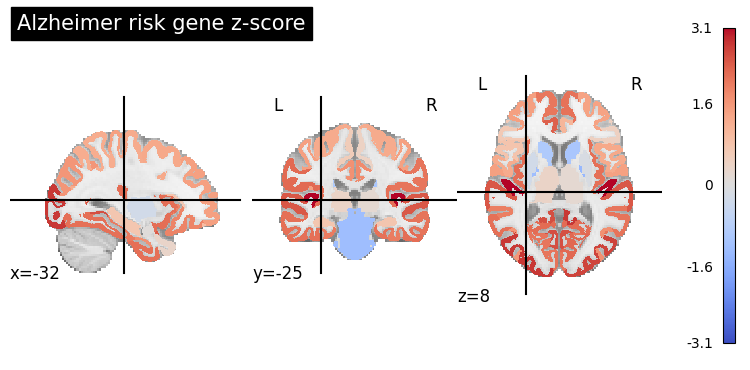

In [45]:
import nibabel as nib
from nilearn import plotting

img = nib.load(atlas['image'])
data = img.get_fdata()
zmap = np.zeros(data.shape)
for rid, zval in zip(expression.index, z):
    zmap[data == rid] = zval

zimg = nib.Nifti1Image(zmap, img.affine)
plotting.plot_stat_map(zimg, cmap='coolwarm', colorbar=True, title='Alzheimer risk gene z-score')

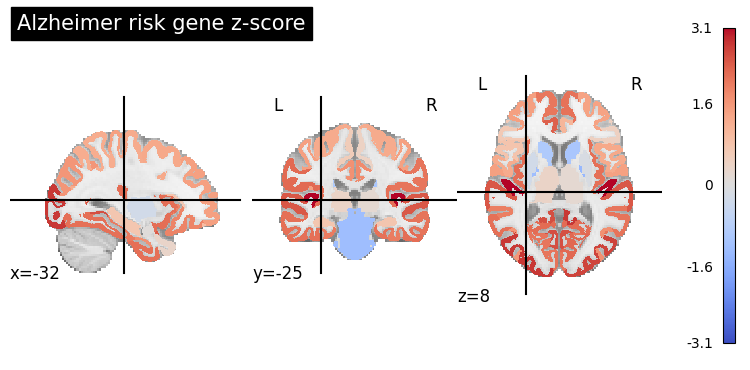

In [48]:
display = plotting.plot_stat_map(zimg, cmap='coolwarm', colorbar=True, title='Alzheimer risk gene z-score')
display.savefig('brain_zscore.png', dpi=200)

The cortex looks the reddest in the brain scans, and the top 10 regions by z-score are all cortical.

In [46]:
results = info.loc[expression.index, ['label', 'hemisphere', 'structure']].copy()
results['z'] = z
results['p'] = p
results['p_corrected'] = p_corrected
print(results.sort_values('z', ascending=False).head(10))
results.to_csv('results.csv')

                    label hemisphere structure         z         p  \
label                                                                
33     transversetemporal          L    cortex  3.127726  0.001000   
74     transversetemporal          R    cortex  3.124866  0.000900   
72            frontalpole          R    cortex  2.792095  0.003000   
10       lateraloccipital          L    cortex  2.780844  0.003700   
50       isthmuscingulate          R    cortex  2.773959  0.003300   
51       lateraloccipital          R    cortex  2.647392  0.004800   
9        isthmuscingulate          L    cortex  2.527339  0.006699   
53                lingual          R    cortex  2.524145  0.006099   
12                lingual          L    cortex  2.519180  0.006299   
29       superiortemporal          L    cortex  2.430713  0.008599   

       p_corrected  
label               
33        0.041496  
74        0.041496  
72        0.055232  
10        0.055232  
50        0.055232  
51        0.

The top 10 regions by z-score were all cortical: transverse temporal (left and right, z about 3.1), right frontal pole (2.79), lateral occipital (left 2.78, right 2.65), isthmus cingulate (right 2.77, left 2.53), lingual (right 2.52, left 2.52) and left superior temporal (2.43). Only the two transverse temporal regions are significant after correction (corrected p = 0.041). The next eight regions have a corrected p of 0.055, just above the 0.05 cutoff.

In [47]:
print(results[results['label'].isin(['entorhinal', 'hippocampus'])])

             label hemisphere            structure         z         p  \
label                                                                    
5       entorhinal          L               cortex  1.706735  0.041996   
40     hippocampus          L  subcortex/brainstem  0.709029  0.241176   
46      entorhinal          R               cortex  1.689016  0.044496   
81     hippocampus          R  subcortex/brainstem  0.743792  0.230177   

       p_corrected  
label               
5         0.081062  
40        0.312775  
46        0.083935  
81        0.307464  


Known Alzheimer's regions: entorhinal cortex z = 1.71 (left) and 1.69 (right), corrected p = 0.081 and 0.084; hippocampus z = 0.71 (left) and 0.74 (right), corrected p = 0.313 and 0.307. None of them is significant after correction. The risk genes are not unusually active in the known early Alzheimer's regions, so in this data risk gene activity alone does not explain where Alzheimer's strikes.

Limitations. Brain regions that sit near each other have similar expression (spatial autocorrelation). My random gene test treats regions as independent, so the p-values may be smaller than they should be. A spin test (for example with neuromaps) would handle this, but I did not run it. Other limits: the expression data comes from only 6 donors, the right hemisphere was copied from the left, and GWAS genes only show DNA variants linked to risk.

Conclusion

I wanted to see if Alzheimer's risk genes are more active in some brain regions than others. I used 474 genes from GWAS (p < 1e-10) and compared their expression across 83 regions against 10,000 random gene lists of the same size.

All top 10 regions by z-score were cortical. After FDR correction only the left and right transverse temporal cortex were significant (z about 3.1, corrected p = 0.041). Right frontal pole, lateral occipital, isthmus cingulate, lingual and superior temporal had z between 2.4 and 2.8, but their corrected p was 0.055, just above the cutoff. I was a bit surprised that the entorhinal cortex (corrected p = 0.081 and 0.084) and the hippocampus (corrected p about 0.31) were not significant, because they are among the first regions damaged in Alzheimer's.

I can't say this proves where Alzheimer's starts. GWAS genes only show DNA variants linked to risk, the expression data comes from 6 healthy donors, and my test does not account for spatial autocorrelation. In this data, risk gene activity does not clearly explain where Alzheimer's strikes, but the genes are not spread evenly across the brain.